# Statistical Analysis - Task Latency

In [69]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

BASE_DIR = Path.cwd()

RESULTS_ROOT_MAIN = BASE_DIR / "batch_results"
RESULTS_ROOT_DA = BASE_DIR / "batch_results_DA"

CONFIG_ROOT_MAIN = RESULTS_ROOT_MAIN
CONFIG_ROOT_DA = RESULTS_ROOT_DA

PAPER_IMG_DIR = Path("paper_images")
PAPER_IMG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "font.family": "CMU Serif",
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
})

SAVEFIG = True
FIGSIZE = (3.0, 2.0)

COORD_LABELS = ["FD", "SD", "CE", "DA"]

ITEM_SPAWNING_TIMES = [90, 120, 150]
N_ROBOTS_LIST = [10, 20, 30]
FAIL_PROBS = [0.33, 0.66, 1.0]
MSG_LOSS_PROBS = [0.1]
MALICIOUS_PCT_SINGLE = [0.0, 0.33, 0.66, 1.0]
MALICIOUS_PCT_EXPECTED = [int(round(100.0 * p)) for p in MALICIOUS_PCT_SINGLE]


def find_log_csv(results_dir):
    csv_files = list(results_dir.glob("*.csv"))
    if not csv_files:
        return []
    exp_like = [p for p in csv_files if "exp_" in p.name]
    return sorted(exp_like) if exp_like else sorted(csv_files)


def choose_col(df, candidates):
    cols = [c for c in df.columns if isinstance(c, str)]
    norm = {c.lower(): c for c in cols}
    for cand in candidates:
        cand_l = cand.lower()
        for lc, orig in norm.items():
            if cand_l in lc:
                return orig
    return None


def pick_fake_help_prob(cfg):
    for k in ["FAKE_HELP_PROB", "FAKE_REQUEST_PROB", "FAKE_FAIL_PROB"]:
        if k in cfg:
            return cfg[k]
    return None


_simtime_cache = {}


def load_simtime_table(results_root):
    key = str(results_root.resolve())
    if key in _simtime_cache:
        return _simtime_cache[key]
    path = results_root / "simTime.csv"
    if not path.exists():
        _simtime_cache[key] = None
        return None
    df_sim = pd.read_csv(path)
    _simtime_cache[key] = df_sim
    return df_sim


def match_simtime(cfg, sim_df):
    if sim_df is None or sim_df.empty:
        return np.nan

    df_m = sim_df.copy()
    col_map = {c.lower(): c for c in df_m.columns}

    def col(name):
        return col_map.get(name.lower())

    c_arch = col("arch")
    if c_arch and "ARCHITECTURE" in cfg:
        df_m = df_m[df_m[c_arch] == cfg.get("ARCHITECTURE")]

    c_nbot = col("Nbot")
    if c_nbot and "N_ROBOTS" in cfg:
        df_m = df_m[df_m[c_nbot] == cfg.get("N_ROBOTS")]

    c_nmal = col("Nmal")
    if c_nmal and "N_MALICIOUS" in cfg:
        df_m = df_m[df_m[c_nmal] == cfg.get("N_MALICIOUS")]

    c_fail = col("failProb")
    if c_fail and "FAIL_PROB" in cfg:
        target_fail = int(round(cfg.get("FAIL_PROB", 0.0) * 100))
        df_m = df_m[df_m[c_fail] == target_fail]

    c_commfail = col("commFailProb")
    if c_commfail and "COMM_FAIL_PROB" in cfg:
        target_comm = int(round(cfg.get("COMM_FAIL_PROB", 0.0) * 1000))
        df_m = df_m[df_m[c_commfail] == target_comm]

    c_arrival = col("arrival")
    if c_arrival and "ITEM_SPAWNING_TIME" in cfg:
        df_m = df_m[df_m[c_arrival] == cfg.get("ITEM_SPAWNING_TIME")]

    c_st = col("simTime")
    if not c_st or df_m.empty:
        return np.nan

    return float(df_m[c_st].mean())


def load_experiment(config_path, results_root, sim_df):
    exp_name = config_path.parent.name
    results_dir = config_path.parent

    if not results_dir.exists():
        return None

    with config_path.open() as f:
        cfg = json.load(f)

    log_csvs = find_log_csv(results_dir)
    if not log_csvs:
        return None

    all_mean_delivery = []
    all_n_delivered = []

    for log_csv in log_csvs:
        df_log = pd.read_csv(log_csv)
        if df_log.empty:
            continue

        time_col = choose_col(df_log, ["simtime", "time"])
        item_col = choose_col(df_log, ["itemid", "item_id", "item"])
        event_col = choose_col(df_log, ["event"])

        if time_col is None or item_col is None or event_col is None:
            continue

        df_create = df_log[df_log[event_col].astype(str).str.lower() == "create"][
            [item_col, time_col]
        ]
        df_deliver = df_log[df_log[event_col].astype(str).str.lower() == "deliver"][
            [item_col, time_col]
        ]

        df_create = df_create.drop_duplicates(subset=item_col, keep="first")
        df_deliver = df_deliver.drop_duplicates(subset=item_col, keep="first")

        df_merged = pd.merge(
            df_create.rename(columns={time_col: "t_create"}),
            df_deliver.rename(columns={time_col: "t_deliver"}),
            on=item_col,
            how="inner",
        )

        if df_merged.empty:
            continue

        delivery_times = df_merged["t_deliver"] - df_merged["t_create"]
        all_mean_delivery.append(float(delivery_times.mean()))
        all_n_delivered.append(int(len(df_merged)))

    mean_delivery_time = float(np.mean(all_mean_delivery)) if all_mean_delivery else np.nan
    n_delivered = float(np.mean(all_n_delivered)) if all_n_delivered else 0.0

    sim_wall_time = match_simtime(cfg, sim_df)

    return {
        "experiment": exp_name,
        "item_spawn_time": cfg.get("ITEM_SPAWNING_TIME"),
        "n_robots": cfg.get("N_ROBOTS"),
        "n_malicious": cfg.get("N_MALICIOUS"),
        "fail_prob": cfg.get("FAIL_PROB"),
        "comm_fail_prob": cfg.get("COMM_FAIL_PROB"),
        "fake_help_prob": pick_fake_help_prob(cfg),
        "architecture": cfg.get("ARCHITECTURE"),
        "mean_delivery_time": mean_delivery_time,
        "successfully_delivered": n_delivered,
        "sim_wall_time": sim_wall_time,
    }


def load_all_experiments(config_root, results_root):
    sim_df = load_simtime_table(results_root)
    rows = [
        load_experiment(cfg, results_root, sim_df)
        for cfg in sorted(config_root.glob("exp_*/config.json"))
    ]
    rows = [r for r in rows if r is not None]
    return pd.DataFrame(rows)


df_main = load_all_experiments(CONFIG_ROOT_MAIN, RESULTS_ROOT_MAIN)
df_da = load_all_experiments(CONFIG_ROOT_DA, RESULTS_ROOT_DA)

dfs = []
if not df_main.empty:
    dfs.append(df_main[df_main["architecture"] != "dynamic-adaptation"])
if not df_da.empty:
    dfs.append(df_da[df_da["architecture"] == "dynamic-adaptation"])

df = pd.concat(dfs, ignore_index=True) if dfs else pd.DataFrame()

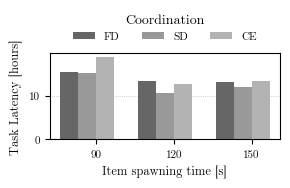

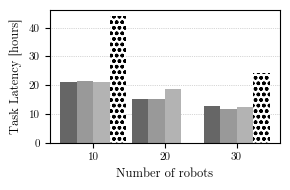

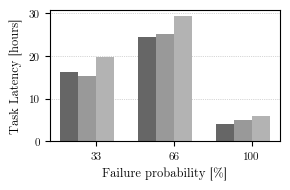

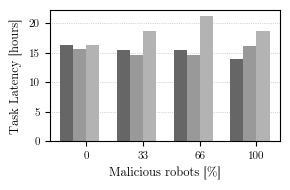

In [70]:
NOMINAL_SCENARIO = {
    "item_spawn_time": 90,
    "n_robots": 20,
    "fail_prob": 0.66,
    "malicious_pct": 0.66,
}

if df.empty:
    print("No experiments found, skipping plots.")
else:
    arch_map = {
        "decentralized": "FD",
        "semi-decentralized": "SD",
        "centralized-impprox": "CE",
        "dynamic-adaptation": "DA",
    }

    df["coord_label"] = df["architecture"].map(arch_map)
    df = df.dropna(subset=["coord_label"])
    df = df[df["n_robots"].isin(N_ROBOTS_LIST)]

    df["mean_delivery_hours"] = df["mean_delivery_time"] / 3600.0

    df["malicious_pct"] = 100.0 * df["n_malicious"] / df["n_robots"]
    allowed_malicious = np.array([0.0, 33.0, 66.0, 100.0])
    df["malicious_pct"] = df["malicious_pct"].apply(
        lambda v: allowed_malicious[np.argmin(np.abs(allowed_malicious - v))]
        if not pd.isna(v) else v
    )

    allowed_fail = np.array([0.33, 0.66, 1.0])

    df["fail_prob"] = df["fail_prob"].astype(float).apply(
        lambda v: allowed_fail[np.argmin(np.abs(allowed_fail - v))]
        if not pd.isna(v) else v
    )
    
    df = df[df["fail_prob"] > 0.0]

    dims = [
        ("item_spawn_time", "Item spawning time [s]", "itemspawn"),
        ("n_robots", "Number of robots", "nrobots"),
        ("fail_prob", "Failure probability [%]", "failprob"),
        ("malicious_pct", "Malicious robots [%]", "malicious"),
    ]

    coord_order = COORD_LABELS
    coord_colors = {
        "FD": "#666666",
        "SD": "#999999",
        "CE": "#b3b3b3",
        "DA": "#ffffff",
    }
    coord_hatches = {
        "FD": "",
        "SD": "",
        "CE": "",
        "DA": "ooo",
    }

    def filter_slice(df_base, dim):
        mask = np.ones(len(df_base), dtype=bool)
    
        if dim != "item_spawn_time":
            mask &= df_base["item_spawn_time"] == NOMINAL_SCENARIO["item_spawn_time"]
        if dim != "n_robots":
            mask &= df_base["n_robots"] == NOMINAL_SCENARIO["n_robots"]

        return df_base[mask]

    def plot_bars(ax, pivot, dim_name, dim_label):
        x_vals = pivot.index.values
        if dim_name == "malicious_pct":
            x_labels = [str(int(round(v))) for v in x_vals]
        elif dim_name == "fail_prob":
            x_labels = [str(int(round(100.0 * v))) for v in x_vals]
        else:
            x_labels = [str(v) for v in x_vals]
        x = np.arange(len(x_vals))

        ax.set_axisbelow(True)
        ax.grid(axis="y", linestyle=":", linewidth=0.5)

        width = 0.23
        for i, coord in enumerate(coord_order):
            if coord not in pivot.columns:
                continue
            y_vals = pivot[coord].values
            offset = (i - (len(coord_order) - 1) / 2.0) * width
            ax.bar(
                x + offset,
                y_vals,
                width,
                label=coord,
                color=coord_colors.get(coord, "#b3b3b3"),
                hatch=coord_hatches.get(coord, ""),
            )

        ax.set_xticks(x)
        ax.set_xticklabels(x_labels)
        ax.set_ylabel("Task Latency [hours]")
        ax.set_xlabel(dim_label)

    first_legend = True

    for dim_name, dim_label, dim_slug in dims:
        df_plot = filter_slice(df, dim_name)
        if df_plot.empty:
            continue

        agg = (
            df_plot.groupby([dim_name, "coord_label"], as_index=False)
            .agg(val=("mean_delivery_hours", "mean"))
        )
        if agg.empty:
            continue

        pivot = agg.pivot(index=dim_name, columns="coord_label", values="val").sort_index()
        if dim_name == "fail_prob":
            pivot = pivot.reindex(allowed_fail)

        fig, ax = plt.subplots(figsize=FIGSIZE)
        plot_bars(ax, pivot, dim_name, dim_label)

        if first_legend:
            handles, labels = ax.get_legend_handles_labels()
            ax.legend(
                handles,
                labels,
                title="Coordination",
                loc="lower center",
                bbox_to_anchor=(0.5, 1.02),
                ncol=len(coord_order),
                frameon=False,
            )

        fig.tight_layout()
        if SAVEFIG:
            fname = f"{dim_slug}_time.pdf"
            fig.savefig(PAPER_IMG_DIR / fname, bbox_inches="tight")
        plt.show()

        if first_legend:
            first_legend = False

# Statistical Analysis - Task Duration